# COVID-WDI Country-Level Analysis

This notebook analyzes the final BigQuery modeling table for the PSTAT 135 COVID-19 project. It documents the full local analysis workflow after completion of the cloud data engineering pipeline: data loading, data quality checks, exploratory data analysis, correlation analysis, PCA, K-Means clustering, Random Forest classification, and final interpretation.

The goal is to identify country-level demographic, economic, and healthcare characteristics associated with higher COVID-19 mortality across countries.


## Imports

Load the libraries needed for data handling, numeric summaries, plotting, and later scikit-learn modeling. The modeling imports are included now so the environment is ready, but no models are fit in this notebook stage.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
plt.style.use("default")

## Data Loading

Load the exported BigQuery table. The expected file is `analysis/exports/country_covid_wdi_modeling.csv`. A second path is included so the notebook also works if it is launched from inside the `analysis/` folder.

In [5]:
DATA_PATH_CANDIDATES = [
    Path("analysis/exports/country_covid_wdi_modeling.csv"),
    Path("exports/country_covid_wdi_modeling.csv"),
    Path("analysis/exports/exports_country_covid_wdi_modeling"),
    Path("exports/exports_country_covid_wdi_modeling"),
]

DATA_PATH = next((path for path in DATA_PATH_CANDIDATES if path.exists()), DATA_PATH_CANDIDATES[0])

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Expected exported BigQuery CSV at analysis/exports/country_covid_wdi_modeling.csv. "
        f"Checked: {[str(path) for path in DATA_PATH_CANDIDATES]}"
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")

Loaded: exports/exports_country_covid_wdi_modeling


## Initial Dataset Display

Display the dataset shape, first rows, and pandas data types. This confirms that the exported table loaded correctly and gives a first look at column types.

In [6]:
print("Dataset shape:")
print(df.shape)

print("\nFirst five rows:")
display(df.head())

Dataset shape:
(209, 20)

First five rows:


,iso3,country_name,region,world_bank_region,population,gdp_per_capita,life_expectancy,population_density,health_expenditure_per_capita,health_expenditure_pct_gdp,pct_age_65_plus,urban_population_pct,confirmed_cases,deaths,cases_per_100k,deaths_per_100k,case_fatality_ratio,population_quartile,mortality_quartile,high_mortality
0,BDI,Burundi,Africa,Sub-Saharan Africa,12255336,234.310616,62.180,477.232710,22.243538,9.059406,2.401268,18.786178,53631,38,437.613461,0.310069,0.000709,Q3,Q1,0
1,NGA,Nigeria,Africa,Sub-Saharan Africa,209485641,3189.812865,53.009,230.009378,67.625443,2.985471,2.974885,58.961119,266598,3155,127.263138,1.506070,0.011834,Q4,Q1,0
2,LBR,Liberia,Africa,Sub-Saharan Africa,5043721,658.164181,61.232,52.364213,51.193237,8.383260,3.210130,52.855262,8090,295,160.397453,5.848856,0.036465,Q2,Q1,0
3,GIN,Guinea,Africa,Sub-Saharan Africa,13034346,1031.341465,59.379,53.045523,42.169102,4.088762,3.456924,36.128155,38267,467,293.585885,3.582842,0.012204,Q3,Q1,0
4,ETH,Ethiopia,Africa,Sub-Saharan Africa,115737383,793.473247,65.741,102.552160,25.935120,3.242871,3.038190,21.248671,500116,7572,432.112760,6.542398,0.015140,Q4,Q1,0


In [7]:
print("DataFrame info:")
df.info()

DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   iso3                           209 non-null    object 
 1   country_name                   209 non-null    object 
 2   region                         209 non-null    object 
 3   world_bank_region              209 non-null    object 
 4   population                     209 non-null    int64  
 5   gdp_per_capita                 203 non-null    float64
 6   life_expectancy                209 non-null    float64
 7   population_density             209 non-null    float64
 8   health_expenditure_per_capita  192 non-null    float64
 9   health_expenditure_pct_gdp     192 non-null    float64
 10  pct_age_65_plus                209 non-null    float64
 11  urban_population_pct           209 non-null    float64
 12  confirmed_cases                209

## Data Quality Checks

Check key identifiers, target variables, quartile labels, and basic value ranges before doing any analysis. These diagnostics help catch export or transformation issues early.

In [8]:
expected_columns = [
    "iso3",
    "country_name",
    "region",
    "world_bank_region",
    "population",
    "gdp_per_capita",
    "life_expectancy",
    "population_density",
    "health_expenditure_per_capita",
    "health_expenditure_pct_gdp",
    "pct_age_65_plus",
    "urban_population_pct",
    "confirmed_cases",
    "deaths",
    "cases_per_100k",
    "deaths_per_100k",
    "case_fatality_ratio",
    "population_quartile",
    "mortality_quartile",
    "high_mortality",
]

missing_expected = [col for col in expected_columns if col not in df.columns]
unexpected_columns = [col for col in df.columns if col not in expected_columns]

print("Missing expected columns:", missing_expected)
print("Unexpected columns:", unexpected_columns)
print("ISO3 unique:", df["iso3"].is_unique if "iso3" in df.columns else "iso3 missing")
print("Duplicate ISO3 rows:", df.duplicated("iso3").sum() if "iso3" in df.columns else "iso3 missing")

Missing expected columns: []
Unexpected columns: []
ISO3 unique: True
Duplicate ISO3 rows: 0


In [9]:
print("Target distribution:")
print(df["high_mortality"].value_counts(dropna=False).sort_index())

print("\nMortality quartile distribution:")
print(df["mortality_quartile"].value_counts(dropna=False).sort_index())

print("\nPopulation quartile distribution:")
print(df["population_quartile"].value_counts(dropna=False).sort_index())

print("\nRegion distribution:")
print(df["region"].value_counts(dropna=False).sort_index())

Target distribution:
high_mortality
0    157
1     52
Name: count, dtype: int64

Mortality quartile distribution:
mortality_quartile
Q1    53
Q2    52
Q3    52
Q4    52
Name: count, dtype: int64

Population quartile distribution:
population_quartile
Q1    53
Q2    52
Q3    52
Q4    52
Name: count, dtype: int64

Region distribution:
region
Africa           54
Asia             41
Europe           55
North America    30
Oceania          16
South America    13
Name: count, dtype: int64


## Missing Value Summary

Summarize missing values by column. This is especially important for health expenditure predictors, which may have less complete coverage than population and demographic variables.

In [10]:
missing_summary = (
    pd.DataFrame(
        {
            "missing_count": df.isna().sum(),
            "missing_pct": df.isna().mean() * 100,
        }
    )
    .sort_values(["missing_count", "missing_pct"], ascending=False)
)

display(missing_summary)
print("Columns with any missing values:", missing_summary.query("missing_count > 0").shape[0])

,missing_count,missing_pct
health_expenditure_per_capita,17,8.133971
health_expenditure_pct_gdp,17,8.133971
gdp_per_capita,6,2.870813
iso3,0,0.000000
country_name,0,0.000000
region,0,0.000000
world_bank_region,0,0.000000
population,0,0.000000
life_expectancy,0,0.000000
population_density,0,0.000000


Columns with any missing values: 3


## Summary Statistics

Review summary statistics for numeric variables, including COVID outcomes, WDI predictors, rates, and the binary target.

In [11]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric columns:")
print(numeric_cols)

display(df[numeric_cols].describe().T)

Numeric columns:
['population', 'gdp_per_capita', 'life_expectancy', 'population_density', 'health_expenditure_per_capita', 'health_expenditure_pct_gdp', 'pct_age_65_plus', 'urban_population_pct', 'confirmed_cases', 'deaths', 'cases_per_100k', 'deaths_per_100k', 'case_fatality_ratio', 'high_mortality']


,count,mean,std,min,25%,50%,75%,max
population,209.0,3.704301e+07,1.418171e+08,10581.000000,1.088709e+06,6.945235e+06,2.603763e+07,1.407745e+09
gdp_per_capita,203.0,1.875226e+04,2.766212e+04,234.310616,2.491052e+03,6.804149e+03,2.380837e+04,1.937468e+05
life_expectancy,209.0,7.287469e+01,8.049772e+00,31.530000,6.700900e+01,7.392000e+01,7.864634e+01,8.615100e+01
population_density,209.0,4.510769e+02,2.053407e+03,0.136984,3.800247e+01,8.886972e+01,2.260268e+02,2.042553e+04
health_expenditure_per_capita,192.0,1.194440e+03,1.962550e+03,12.990744,7.818093e+01,3.700218e+02,1.190803e+03,1.055022e+04
health_expenditure_pct_gdp,192.0,6.524342e+00,3.181320e+00,2.127126,4.259129e+00,5.765058e+00,8.343189e+00,2.222294e+01
pct_age_65_plus,209.0,9.351855e+00,6.616974e+00,1.172120,3.777016e+00,7.015988e+00,1.447007e+01,3.628539e+01
urban_population_pct,209.0,6.113139e+01,2.342803e+01,13.927827,4.178004e+01,6.235422e+01,7.957800e+01,1.000000e+02
confirmed_cases,209.0,3.182371e+06,9.910700e+06,1.000000,3.465800e+04,2.714960e+05,1.498668e+06,1.038027e+08
deaths,209.0,3.280850e+04,1.088071e+05,0.000000,2.950000e+02,2.808000e+03,1.788100e+04,1.123836e+06


## Exploratory Distribution Plots

Plot key distributions. The project's mortality-per-100k measure is stored as `deaths_per_100k` in the modeling table.

Distribution columns: ['deaths_per_100k', 'cases_per_100k', 'gdp_per_capita', 'life_expectancy']


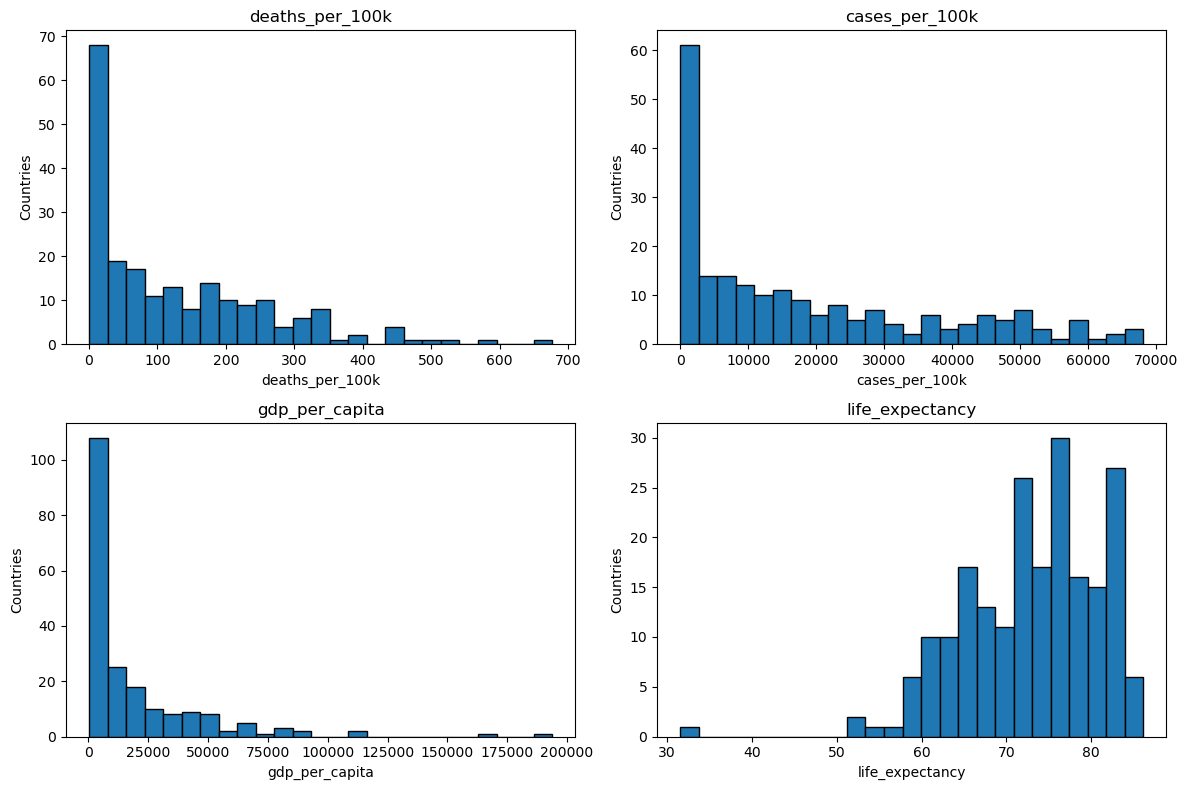

In [12]:
distribution_cols = [
    "deaths_per_100k",
    "cases_per_100k",
    "gdp_per_capita",
    "life_expectancy",
]

available_distribution_cols = [col for col in distribution_cols if col in df.columns]
print("Distribution columns:", available_distribution_cols)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, col in zip(axes, available_distribution_cols):
    ax.hist(df[col].dropna(), bins=25, edgecolor="black")
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Countries")

for ax in axes[len(available_distribution_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Distribution Interpretation

The distribution plots show that `deaths_per_100k` is right-skewed: most countries have lower or moderate COVID-19 mortality rates, while a smaller number of countries experienced much higher mortality. This supports using both continuous mortality rates and a highest-quartile target for classification.

`cases_per_100k` is also right-skewed, reflecting large cross-country differences in confirmed case burden. This pattern should be interpreted cautiously because confirmed cases depend heavily on testing capacity, reporting systems, and national surveillance practices.

`gdp_per_capita` is strongly right-skewed, with a small number of very high-income countries far above the rest of the sample. This matters for PCA and K-Means because extreme economic values can influence distances and component structure even after standardization.

`life_expectancy` is comparatively more symmetric than the economic and COVID burden variables, although it still shows meaningful variation across countries. Overall, these skewed and outlier-prone distributions mean cross-country comparisons should emphasize rates, standardized predictors, and careful interpretation rather than raw totals alone.


## Correlation Analysis

Compute and visualize correlations among numeric variables. This helps identify redundant predictors and relationships with the main outcome `deaths_per_100k`.

In [13]:
correlation_matrix = df[numeric_cols].corr()
display(correlation_matrix)

if "deaths_per_100k" in correlation_matrix.columns:
    print("Correlations with deaths_per_100k:")
    display(correlation_matrix["deaths_per_100k"].sort_values(ascending=False))

,population,gdp_per_capita,life_expectancy,population_density,health_expenditure_per_capita,health_expenditure_pct_gdp,pct_age_65_plus,urban_population_pct,confirmed_cases,deaths,cases_per_100k,deaths_per_100k,case_fatality_ratio,high_mortality
population,1.000000,-0.069855,-0.001059,-0.027705,-0.015236,-0.078408,-0.010568,-0.056784,0.383951,0.448376,-0.134451,-0.078836,-0.000445,-0.036531
gdp_per_capita,-0.069855,1.000000,0.599893,0.460252,0.884595,0.193626,0.591676,0.438047,0.150821,0.052753,0.600947,0.193865,-0.341603,0.133668
life_expectancy,-0.001059,0.599893,1.000000,0.222924,0.601819,0.197975,0.704567,0.589000,0.228854,0.136307,0.666030,0.494459,-0.009451,0.362441
population_density,-0.027705,0.460252,0.222924,1.000000,0.248374,-0.069035,0.229953,0.242194,-0.034002,-0.045242,0.090520,-0.021171,-0.008512,-0.064393
health_expenditure_per_capita,-0.015236,0.884595,0.601819,0.248374,1.000000,0.416762,0.651359,0.447264,0.423376,0.267469,0.655166,0.275381,-0.269643,0.218742
health_expenditure_pct_gdp,-0.078408,0.193626,0.197975,-0.069035,0.416762,1.000000,0.349599,0.248024,0.292454,0.206426,0.378065,0.268720,-0.043409,0.264205
pct_age_65_plus,-0.010568,0.591676,0.704567,0.229953,0.651359,0.349599,1.000000,0.438675,0.280682,0.154263,0.698896,0.651459,0.007659,0.542337
urban_population_pct,-0.056784,0.438047,0.589000,0.242194,0.447264,0.248024,0.438675,1.000000,0.185715,0.140543,0.479417,0.324691,-0.005240,0.230569
confirmed_cases,0.383951,0.150821,0.228854,-0.034002,0.423376,0.292454,0.280682,0.185715,1.000000,0.878771,0.191871,0.211730,-0.025026,0.224818
deaths,0.448376,0.052753,0.136307,-0.045242,0.267469,0.206426,0.154263,0.140543,0.878771,1.000000,0.041998,0.280118,-0.018703,0.296859


Correlations with deaths_per_100k:


deaths_per_100k                  1.000000
high_mortality                   0.830582
pct_age_65_plus                  0.651459
cases_per_100k                   0.497994
life_expectancy                  0.494459
urban_population_pct             0.324691
deaths                           0.280118
health_expenditure_per_capita    0.275381
health_expenditure_pct_gdp       0.268720
confirmed_cases                  0.211730
gdp_per_capita                   0.193865
population_density              -0.021171
case_fatality_ratio             -0.066801
population                      -0.078836
Name: deaths_per_100k, dtype: float64

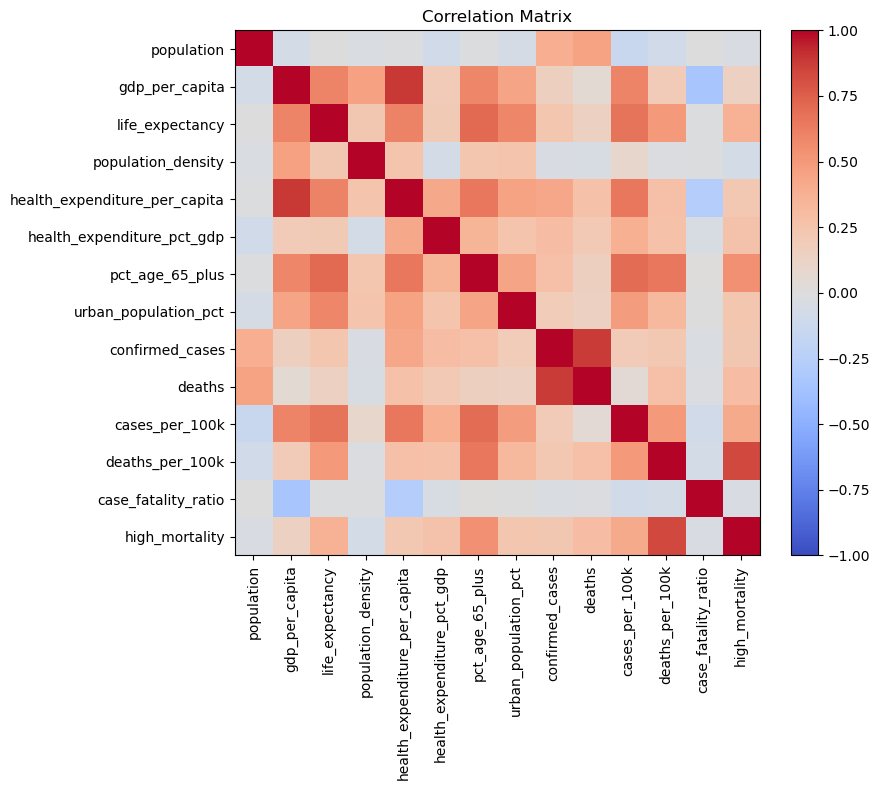

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(correlation_matrix, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(np.arange(len(correlation_matrix.columns)))
ax.set_yticks(np.arange(len(correlation_matrix.index)))
ax.set_xticklabels(correlation_matrix.columns, rotation=90)
ax.set_yticklabels(correlation_matrix.index)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

### Correlation Interpretation

The strongest observed positive association with `deaths_per_100k` is `pct_age_65_plus` (approximately 0.65). This suggests that countries with older populations tended to experience higher COVID-19 mortality rates, which is consistent with known age-related mortality risk.

`cases_per_100k` is also positively correlated with `deaths_per_100k` (approximately 0.50), indicating that countries with higher confirmed case burden often had higher mortality burden. This relationship is meaningful but should be interpreted cautiously because confirmed cases depend on testing and reporting.

`life_expectancy` is positively correlated with `deaths_per_100k` (approximately 0.49). In this country-level dataset, life expectancy likely reflects broader development and age-structure patterns rather than a direct protective or harmful causal effect.

Healthcare expenditure variables show moderate positive associations with mortality: `health_expenditure_per_capita` and `health_expenditure_pct_gdp` are both around 0.27. This does not mean healthcare spending caused higher mortality. More likely, these variables are correlated with older populations, better reporting systems, and higher-income country profiles.

These correlations are useful for identifying patterns, but they do not establish causation. The analysis is cross-sectional and country-level, so all correlation findings should be interpreted as associations.


## Identify Modeling Variables

Identify candidate columns for PCA, K-Means, and Random Forest. This section defines variable groups only; it does not fit PCA, clustering, or classification models.

In [15]:
structural_predictor_cols = [
    "population",
    "gdp_per_capita",
    "life_expectancy",
    "population_density",
    "health_expenditure_per_capita",
    "health_expenditure_pct_gdp",
    "pct_age_65_plus",
    "urban_population_pct",
]

covid_profile_cols = [
    "confirmed_cases",
    "deaths",
    "cases_per_100k",
    "deaths_per_100k",
    "case_fatality_ratio",
]

pca_cols = [col for col in structural_predictor_cols if col in df.columns]
kmeans_cols = [col for col in structural_predictor_cols + ["cases_per_100k", "deaths_per_100k", "case_fatality_ratio"] if col in df.columns]
rf_feature_cols = [col for col in structural_predictor_cols if col in df.columns]
target_col = "high_mortality"

print("PCA candidate columns:")
print(pca_cols)

print("\nK-Means candidate columns:")
print(kmeans_cols)

print("\nRandom Forest candidate feature columns:")
print(rf_feature_cols)

print("\nRandom Forest target column:")
print(target_col)

print("\nExcluded from Random Forest features to avoid target leakage:")
print(["confirmed_cases", "deaths", "cases_per_100k", "deaths_per_100k", "case_fatality_ratio", "mortality_quartile", "high_mortality"])

print("\nDescriptive/grouping columns not used as primary predictors:")
print(["iso3", "country_name", "region", "world_bank_region", "population_quartile", "mortality_quartile"])

PCA candidate columns:
['population', 'gdp_per_capita', 'life_expectancy', 'population_density', 'health_expenditure_per_capita', 'health_expenditure_pct_gdp', 'pct_age_65_plus', 'urban_population_pct']

K-Means candidate columns:
['population', 'gdp_per_capita', 'life_expectancy', 'population_density', 'health_expenditure_per_capita', 'health_expenditure_pct_gdp', 'pct_age_65_plus', 'urban_population_pct', 'cases_per_100k', 'deaths_per_100k', 'case_fatality_ratio']

Random Forest candidate feature columns:
['population', 'gdp_per_capita', 'life_expectancy', 'population_density', 'health_expenditure_per_capita', 'health_expenditure_pct_gdp', 'pct_age_65_plus', 'urban_population_pct']

Random Forest target column:
high_mortality

Excluded from Random Forest features to avoid target leakage:
['confirmed_cases', 'deaths', 'cases_per_100k', 'deaths_per_100k', 'case_fatality_ratio', 'mortality_quartile', 'high_mortality']

Descriptive/grouping columns not used as primary predictors:
['iso3'

In [16]:
modeling_missingness = pd.DataFrame(
    {
        "pca_missing_count": df[pca_cols].isna().sum() if pca_cols else pd.Series(dtype=int),
        "rf_missing_count": df[rf_feature_cols].isna().sum() if rf_feature_cols else pd.Series(dtype=int),
    }
)

display(modeling_missingness)
print("Rows with complete PCA candidate features:", df[pca_cols].dropna().shape[0] if pca_cols else 0)
print("Rows with complete Random Forest candidate features:", df[rf_feature_cols].dropna().shape[0] if rf_feature_cols else 0)

,pca_missing_count,rf_missing_count
population,0,0
gdp_per_capita,6,6
life_expectancy,0,0
population_density,0,0
health_expenditure_per_capita,17,17
health_expenditure_pct_gdp,17,17
pct_age_65_plus,0,0
urban_population_pct,0,0


Rows with complete PCA candidate features: 189
Rows with complete Random Forest candidate features: 189


## PCA

Principal Component Analysis (PCA) reduces a set of correlated numeric predictors into a smaller number of uncorrelated components. Each principal component is a weighted combination of the original variables. The first component explains the largest possible share of variance, the second explains the next largest share, and so on.

For this project, PCA is used for dimensionality reduction and visualization of country-level demographic, economic, and healthcare predictors. It is not fit on identifiers, region labels, quartile labels, or the supervised target.

### PCA Feature Selection

Use only continuous numeric predictor variables. The PCA input excludes identifiers, region fields, quartile fields, the `high_mortality` target, and COVID outcome/rate variables so the components represent country characteristics rather than the response variable.

In [17]:
pca_predictor_cols = [
    "population",
    "gdp_per_capita",
    "life_expectancy",
    "population_density",
    "health_expenditure_per_capita",
    "health_expenditure_pct_gdp",
    "pct_age_65_plus",
    "urban_population_pct",
]

pca_excluded_cols = [
    "iso3",
    "country_name",
    "region",
    "world_bank_region",
    "population_quartile",
    "mortality_quartile",
    "high_mortality",
]

missing_pca_cols = [col for col in pca_predictor_cols if col not in df.columns]
if missing_pca_cols:
    raise ValueError(f"Missing expected PCA columns: {missing_pca_cols}")

X_pca_raw = df[pca_predictor_cols].copy()

print("PCA predictor columns:")
print(pca_predictor_cols)
print("\nExcluded non-PCA columns:")
print(pca_excluded_cols)
print("\nPCA input shape before imputation/scaling:", X_pca_raw.shape)
print("\nMissing values in PCA predictors:")
display(X_pca_raw.isna().sum().to_frame("missing_count"))


PCA predictor columns:
['population', 'gdp_per_capita', 'life_expectancy', 'population_density', 'health_expenditure_per_capita', 'health_expenditure_pct_gdp', 'pct_age_65_plus', 'urban_population_pct']

Excluded non-PCA columns:
['iso3', 'country_name', 'region', 'world_bank_region', 'population_quartile', 'mortality_quartile', 'high_mortality']

PCA input shape before imputation/scaling: (209, 8)

Missing values in PCA predictors:


,missing_count
population,0
gdp_per_capita,6
life_expectancy,0
population_density,0
health_expenditure_per_capita,17
health_expenditure_pct_gdp,17
pct_age_65_plus,0
urban_population_pct,0


### Imputation, Standardization, and PCA Fit

Median imputation fills missing predictor values using the median of each variable. Standardization is required because PCA is scale-sensitive: variables such as population and GDP per capita are measured on very different scales. After imputation and scaling, PCA is fit on the standardized predictor matrix.

In [18]:
pca_imputer = SimpleImputer(strategy="median")
pca_scaler = StandardScaler()
pca_model = PCA()

X_pca_imputed = pca_imputer.fit_transform(X_pca_raw)
X_pca_scaled = pca_scaler.fit_transform(X_pca_imputed)
pca_scores_array = pca_model.fit_transform(X_pca_scaled)

component_names = [f"PC{i}" for i in range(1, len(pca_predictor_cols) + 1)]

pca_scores = pd.DataFrame(
    pca_scores_array,
    columns=component_names,
    index=df.index,
)

pca_scores = pd.concat(
    [df[["iso3", "country_name", "region", "high_mortality"]].reset_index(drop=True), pca_scores.reset_index(drop=True)],
    axis=1,
)

print("PCA fitted on standardized predictors.")
print("PCA score table shape:", pca_scores.shape)
display(pca_scores.head())

PCA fitted on standardized predictors.
PCA score table shape: (209, 12)


,iso3,country_name,region,high_mortality,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,BDI,Burundi,Africa,0,-2.066856,0.680378,-0.376713,-1.593518,0.246454,0.292199,0.359074,0.129187
1,NGA,Nigeria,Africa,0,-2.344055,-0.767562,0.931619,-0.490729,0.290166,-1.097691,-1.415577,-0.021808
2,LBR,Liberia,Africa,0,-1.615129,0.603502,-0.449371,-0.621449,0.725371,-0.384613,-0.274575,0.129262
3,GIN,Guinea,Africa,0,-2.254912,-0.299728,-0.293764,-0.653392,-0.357275,-0.259470,-0.532414,-0.095144
4,ETH,Ethiopia,Africa,0,-2.248835,-0.579923,0.527703,-0.685292,-0.772882,0.150886,0.204372,-0.152880


### Explained Variance

The explained variance ratio shows how much of the standardized predictor variance is captured by each component. The cumulative explained variance shows how much variance is captured as components are added.

In [19]:
explained_variance = pd.DataFrame(
    {
        "component": component_names,
        "explained_variance_ratio": pca_model.explained_variance_ratio_,
        "cumulative_explained_variance": np.cumsum(pca_model.explained_variance_ratio_),
    }
)

print("Explained variance ratio table:")
display(explained_variance[["component", "explained_variance_ratio"]])

print("Cumulative explained variance table:")
display(explained_variance[["component", "cumulative_explained_variance"]])

thresholds = [0.70, 0.80, 0.90]
for threshold in thresholds:
    n_components = int((explained_variance["cumulative_explained_variance"] >= threshold).idxmax() + 1)
    print(f"Components needed to explain at least {threshold:.0%} variance: {n_components}")

Explained variance ratio table:


,component,explained_variance_ratio
0,PC1,0.441668
1,PC2,0.146114
2,PC3,0.126677
3,PC4,0.095112
4,PC5,0.082927
5,PC6,0.059253
6,PC7,0.030216
7,PC8,0.018034


Cumulative explained variance table:


,component,cumulative_explained_variance
0,PC1,0.441668
1,PC2,0.587782
2,PC3,0.714459
3,PC4,0.809571
4,PC5,0.892497
5,PC6,0.951750
6,PC7,0.981966
7,PC8,1.000000


Components needed to explain at least 70% variance: 3
Components needed to explain at least 80% variance: 4
Components needed to explain at least 90% variance: 6


### Variance Plots

The scree plot shows the variance explained by each principal component. The cumulative variance plot helps decide how many components capture most of the information in the predictor set.

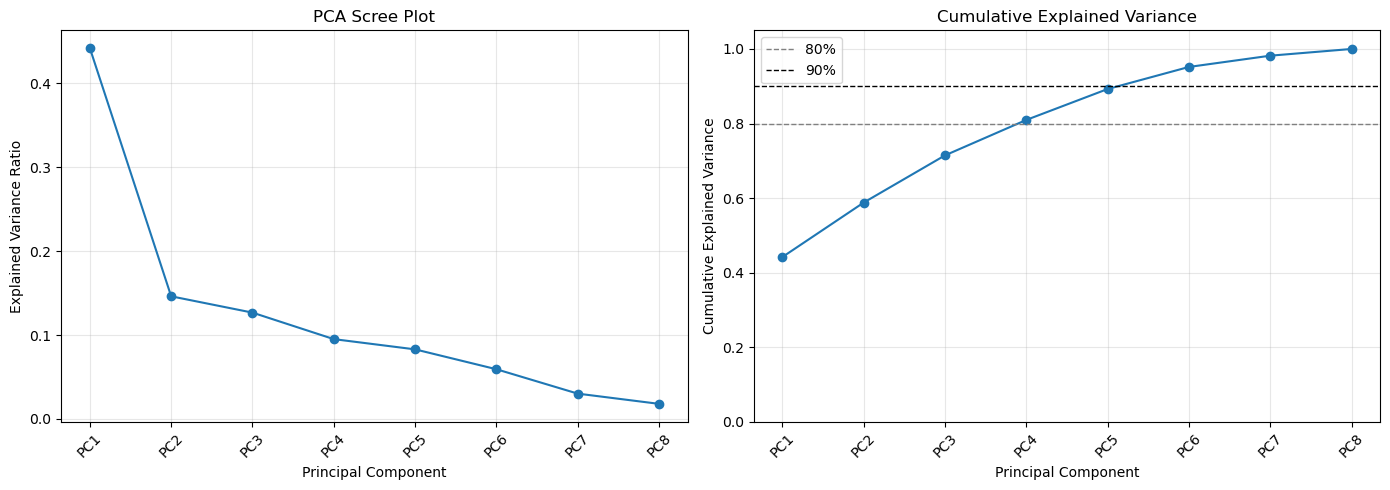

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(explained_variance["component"], explained_variance["explained_variance_ratio"], marker="o")
axes[0].set_title("PCA Scree Plot")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, alpha=0.3)

axes[1].plot(explained_variance["component"], explained_variance["cumulative_explained_variance"], marker="o")
axes[1].axhline(0.80, color="gray", linestyle="--", linewidth=1, label="80%")
axes[1].axhline(0.90, color="black", linestyle="--", linewidth=1, label="90%")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Principal Component")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

### PCA Loadings

PCA loadings show how strongly each original variable contributes to each principal component. Large positive or negative loadings indicate variables that strongly shape a component.

In [21]:
loadings = pd.DataFrame(
    pca_model.components_.T,
    index=pca_predictor_cols,
    columns=component_names,
)

print("PCA loadings table:")
display(loadings)

pc1_top_loadings = loadings["PC1"].abs().sort_values(ascending=False).head(5)
pc2_top_loadings = loadings["PC2"].abs().sort_values(ascending=False).head(5)

print("Variables contributing most strongly to PC1 by absolute loading:")
display(loadings.loc[pc1_top_loadings.index, ["PC1"]].sort_values("PC1", key=lambda s: s.abs(), ascending=False))

print("Variables contributing most strongly to PC2 by absolute loading:")
display(loadings.loc[pc2_top_loadings.index, ["PC2"]].sort_values("PC2", key=lambda s: s.abs(), ascending=False))

PCA loadings table:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
population,-0.031582,-0.093801,0.971974,-0.099531,0.170439,-0.055851,-0.006350,0.057921
gdp_per_capita,0.448638,-0.208634,-0.044470,-0.285831,-0.286744,-0.321986,0.014503,0.696715
life_expectancy,0.439180,-0.051272,0.098683,0.411539,-0.128745,0.284973,0.723933,-0.059378
population_density,0.212896,-0.658358,-0.156117,-0.423084,0.467409,0.194763,0.073036,-0.236918
health_expenditure_per_capita,0.436790,0.212553,0.073999,-0.307078,-0.312299,-0.386042,-0.041923,-0.644939
health_expenditure_pct_gdp,0.212350,0.674874,-0.062090,-0.345475,0.541130,0.104285,0.194313,0.186519
pct_age_65_plus,0.440019,0.086930,0.087306,0.070998,-0.147082,0.644214,-0.590590,0.026872
urban_population_pct,0.360595,-0.058468,-0.047167,0.584242,0.491627,-0.446260,-0.286397,-0.010970


Variables contributing most strongly to PC1 by absolute loading:


,PC1
gdp_per_capita,0.448638
pct_age_65_plus,0.440019
life_expectancy,0.439180
health_expenditure_per_capita,0.436790
urban_population_pct,0.360595


Variables contributing most strongly to PC2 by absolute loading:


,PC2
health_expenditure_pct_gdp,0.674874
population_density,-0.658358
health_expenditure_per_capita,0.212553
gdp_per_capita,-0.208634
population,-0.093801


### PC1 vs PC2 Visualization

The PC1 vs PC2 scatter plot visualizes countries in the first two principal-component dimensions. Colors show the `high_mortality` class for interpretation only; the target was not used to fit PCA.

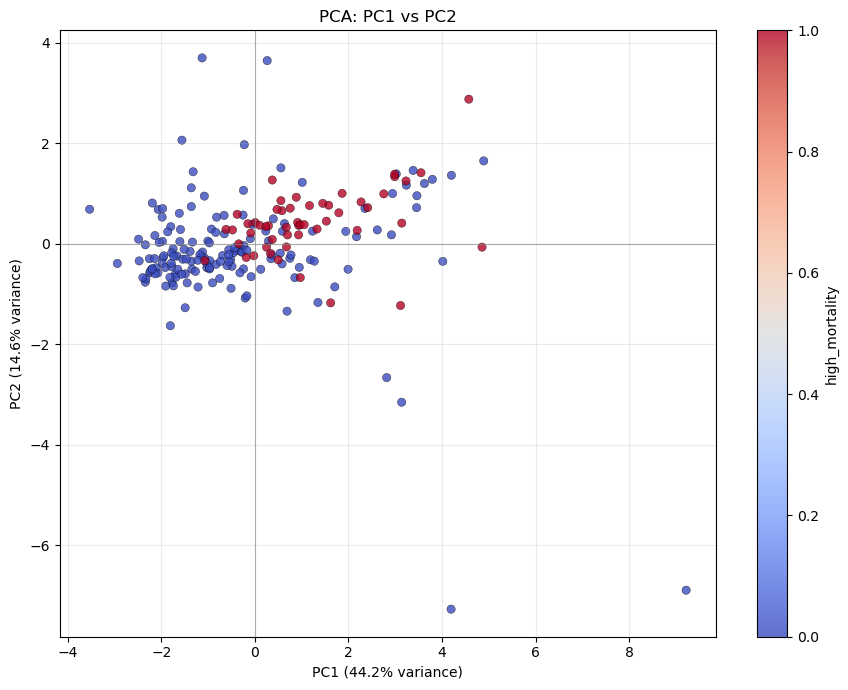

In [22]:
fig, ax = plt.subplots(figsize=(9, 7))

scatter = ax.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    c=pca_scores["high_mortality"],
    cmap="coolwarm",
    alpha=0.8,
    edgecolor="black",
    linewidth=0.3,
)

ax.axhline(0, color="gray", linewidth=0.8, alpha=0.6)
ax.axvline(0, color="gray", linewidth=0.8, alpha=0.6)
ax.set_title("PCA: PC1 vs PC2")
ax.set_xlabel(f"PC1 ({explained_variance.loc[0, 'explained_variance_ratio']:.1%} variance)")
ax.set_ylabel(f"PC2 ({explained_variance.loc[1, 'explained_variance_ratio']:.1%} variance)")
ax.grid(True, alpha=0.25)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("high_mortality")

plt.tight_layout()
plt.show()

### PCA Interpretation

The PCA results show that PC1 captures the main development-related dimension in the predictor set. PC1 explains approximately 44% of the standardized predictor variance, and its largest loadings come from `gdp_per_capita`, `pct_age_65_plus`, `life_expectancy`, `health_expenditure_per_capita`, and `urban_population_pct`. Countries with high PC1 scores therefore tend to be wealthier, older, longer-lived, more urbanized, and higher-spending on healthcare.

PC2 captures a different contrast. Based on the loading table, PC2 is strongly positive for `health_expenditure_pct_gdp` and strongly negative for `population_density`, with a smaller positive contribution from `health_expenditure_per_capita`. High PC2 scores therefore tend to represent countries spending a larger share of GDP on healthcare without being especially high-density. Low PC2 scores tend to represent very dense countries, especially where density is the dominant structural feature.

The PC1 vs PC2 scatterplot should be interpreted as a visualization of structural country profiles. High-mortality countries do not form a perfectly separate group, but they appear more concentrated along the development/age-structure dimensions captured by PC1. This partial separation is consistent with the EDA and correlation findings: older population structure, higher life expectancy, GDP per capita, and health spending are associated with higher mortality rates, but they do not fully determine outcomes.

Overall, PCA supports the idea that a small number of demographic-development dimensions summarize much of the predictor variation. Four principal components explain roughly 81% of the variance, which indicates that the eight predictors contain substantial shared structure.


## K-Means Clustering

K-Means clustering is an unsupervised learning method that groups countries based on similarity across the selected predictor variables. Here, K-Means uses the same continuous country-level predictors as PCA so the clustering structure can be compared directly with the PCA visualization.

### K-Means Preprocessing

K-Means is distance-based, so scaling is required. Without standardization, variables with large numeric ranges, such as population or GDP per capita, would dominate the distance calculations. This section reuses the PCA preprocessing: median imputation followed by `StandardScaler`.

In [23]:
# Reuse the same predictor matrix and preprocessing used for PCA.
# X_pca_scaled was created from pca_predictor_cols using median imputation and StandardScaler.
X_kmeans = X_pca_scaled.copy()

print("K-Means predictor columns:")
print(pca_predictor_cols)
print("\nK-Means input shape:", X_kmeans.shape)
print("\nPreprocessing reused from PCA: median imputation + StandardScaler")


K-Means predictor columns:
['population', 'gdp_per_capita', 'life_expectancy', 'population_density', 'health_expenditure_per_capita', 'health_expenditure_pct_gdp', 'pct_age_65_plus', 'urban_population_pct']

K-Means input shape: (209, 8)

Preprocessing reused from PCA: median imputation + StandardScaler


### Elbow Method

The elbow method compares K-Means inertia across different values of `k`. Inertia measures within-cluster compactness; lower values are better, but inertia always decreases as `k` increases. The goal is to look for a point where the improvement starts to flatten.

,k,inertia
0,1,1672.000000
1,2,1189.937459
2,3,983.541253
3,4,796.153343
4,5,619.900173
5,6,540.352412
6,7,474.439388
7,8,436.679088
8,9,400.069841
9,10,365.481826


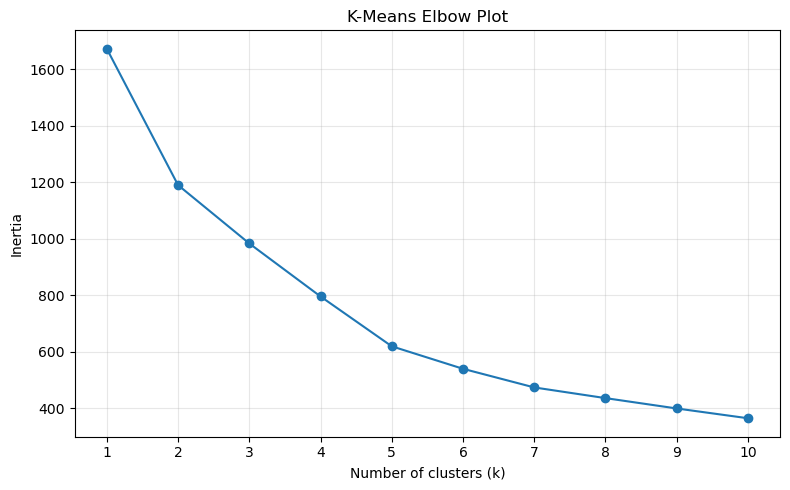

In [24]:
k_values = range(1, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_kmeans)
    inertias.append(model.inertia_)

elbow_df = pd.DataFrame({"k": list(k_values), "inertia": inertias})
display(elbow_df)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(elbow_df["k"], elbow_df["inertia"], marker="o")
ax.set_title("K-Means Elbow Plot")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
ax.set_xticks(list(k_values))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Fit K-Means Models

Fit two candidate clustering solutions: `k = 3` and `k = 4`. Both use `random_state=42` for reproducibility and `n_init=10`, which is appropriate for current scikit-learn versions.

In [25]:
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

cluster_labels_3 = kmeans_3.fit_predict(X_kmeans)
cluster_labels_4 = kmeans_4.fit_predict(X_kmeans)

cluster_assignments_3 = df[["iso3", "country_name", "region"]].copy()
cluster_assignments_3["cluster_k3"] = cluster_labels_3

cluster_assignments_4 = df[["iso3", "country_name", "region"]].copy()
cluster_assignments_4["cluster_k4"] = cluster_labels_4

print("k=3 cluster assignments preview:")
display(cluster_assignments_3.head())

print("k=4 cluster assignments preview:")
display(cluster_assignments_4.head())

k=3 cluster assignments preview:


,iso3,country_name,region,cluster_k3
0,BDI,Burundi,Africa,1
1,NGA,Nigeria,Africa,1
2,LBR,Liberia,Africa,1
3,GIN,Guinea,Africa,1
4,ETH,Ethiopia,Africa,1


k=4 cluster assignments preview:


,iso3,country_name,region,cluster_k4
0,BDI,Burundi,Africa,0
1,NGA,Nigeria,Africa,0
2,LBR,Liberia,Africa,0
3,GIN,Guinea,Africa,0
4,ETH,Ethiopia,Africa,0


### Cluster Sizes

Cluster size tables show whether the solutions create reasonably balanced groups or isolate very small sets of countries.

In [26]:
cluster_size_k3 = cluster_assignments_3["cluster_k3"].value_counts().sort_index().to_frame("country_count")
cluster_size_k4 = cluster_assignments_4["cluster_k4"].value_counts().sort_index().to_frame("country_count")

print("Cluster sizes for k=3:")
display(cluster_size_k3)

print("Cluster sizes for k=4:")
display(cluster_size_k4)

Cluster sizes for k=3:


,country_count
cluster_k3,
0,82
1,125
2,2


Cluster sizes for k=4:


,country_count
cluster_k4,
0,123
1,82
2,2
3,2


### Cluster Centroids

Centroids summarize the average feature profile of each cluster. The standardized centroid table is best for interpretation because values above zero are above the global mean and values below zero are below the global mean. The original-scale centroid table is easier to read in the original units.

In [27]:
def make_centroid_tables(kmeans_model, cluster_col):
    standardized_centroids = pd.DataFrame(
        kmeans_model.cluster_centers_,
        columns=pca_predictor_cols,
    )
    standardized_centroids.insert(0, "cluster", standardized_centroids.index)

    original_centroids = pd.DataFrame(
        pca_scaler.inverse_transform(kmeans_model.cluster_centers_),
        columns=pca_predictor_cols,
    )
    original_centroids.insert(0, "cluster", original_centroids.index)

    return standardized_centroids, original_centroids

centroids_k3_std, centroids_k3_original = make_centroid_tables(kmeans_3, "cluster_k3")
centroids_k4_std, centroids_k4_original = make_centroid_tables(kmeans_4, "cluster_k4")

print("Standardized centroids for k=3:")
display(centroids_k3_std)
print("Original-scale centroids for k=3:")
display(centroids_k3_original)

print("Standardized centroids for k=4:")
display(centroids_k4_std)
print("Original-scale centroids for k=4:")
display(centroids_k4_original)

Standardized centroids for k=3:


,cluster,population,gdp_per_capita,life_expectancy,population_density,health_expenditure_per_capita,health_expenditure_pct_gdp,pct_age_65_plus,urban_population_pct
0,0,-0.115613,0.655708,0.827766,-0.004409,0.679143,0.493270,0.901827,0.700705
1,1,0.079991,-0.500207,-0.567253,-0.146775,-0.469364,-0.314977,-0.625778,-0.486271
2,2,-0.259320,4.378956,1.514907,9.354229,1.490380,-0.538030,2.136229,1.663048


Original-scale centroids for k=3:


,cluster,population,gdp_per_capita,life_expectancy,population_density,health_expenditure_per_capita,health_expenditure_pct_gdp,pct_age_65_plus,urban_population_pct
0,0,2.068638e+07,36289.107099,79.522059,442.044257,2410.705407,7.966226,15.304924,77.508211
1,1,4.835997e+07,4769.585768,68.319371,150.409831,240.461925,5.502433,5.221017,49.766295
2,2,3.550545e+05,137814.741050,85.040134,19613.111295,3943.637596,4.822498,23.453371,100.000000


Standardized centroids for k=4:


,cluster,population,gdp_per_capita,life_expectancy,population_density,health_expenditure_per_capita,health_expenditure_pct_gdp,pct_age_65_plus,urban_population_pct
0,0,-0.075169,-0.501056,-0.579450,-0.148030,-0.469875,-0.307545,-0.635437,-0.485225
1,1,-0.115613,0.655708,0.827766,-0.004409,0.679143,0.493270,0.901827,0.700705
2,2,9.622348,-0.448037,0.182842,-0.069568,-0.437940,-0.772065,-0.031727,-0.550637
3,3,-0.259320,4.378956,1.514907,9.354229,1.490380,-0.538030,2.136229,1.663048


Original-scale centroids for k=4:


,cluster,population,gdp_per_capita,life_expectancy,population_density,health_expenditure_per_capita,health_expenditure_pct_gdp,pct_age_65_plus,urban_population_pct
0,0,2.640830e+07,4746.454402,68.221426,147.838175,239.496404,5.525089,5.157254,49.790756
1,1,2.068638e+07,36289.107099,79.522059,442.044257,2410.705407,7.966226,15.304924,77.508211
2,2,1.398388e+09,6192.164795,74.343000,308.566681,299.841473,4.109083,9.142420,48.261937
3,3,3.550545e+05,137814.741050,85.040134,19613.111295,3943.637596,4.822498,23.453371,100.000000


### Summary Statistics by Cluster

These tables summarize the original predictor variables by cluster. They help translate the cluster labels into country profiles.

In [28]:
df_clusters = df.copy()
df_clusters["cluster_k3"] = cluster_labels_3
df_clusters["cluster_k4"] = cluster_labels_4

summary_k3 = df_clusters.groupby("cluster_k3")[pca_predictor_cols].agg(["mean", "median"])
summary_k4 = df_clusters.groupby("cluster_k4")[pca_predictor_cols].agg(["mean", "median"])

print("Summary statistics by cluster for k=3:")
display(summary_k3)

print("Summary statistics by cluster for k=4:")
display(summary_k4)

Summary statistics by cluster for k=3:


population             gdp_per_capita                life_expectancy            population_density                \
                    mean      median           mean         median            mean     median               mean        median   
cluster_k3                                                                                                                       
0           2.068638e+07   4988004.5   36653.118924   30645.890602       79.522059  80.397500         442.044257    105.144953   
1           4.835997e+07  10671891.0    4684.812290    3304.118001       68.319371  69.680000         150.409831     81.135779   
2           3.550545e+05    355054.5  137814.741050  137814.741050       85.040134  85.040134       19613.111295  19613.111295   

           health_expenditure_per_capita              health_expenditure_pct_gdp           pct_age_65_plus             \
                                    mean       median                       mean    median            mean     median   
cluster_k3                                                                                                              
0                            2830.846154  1905.159790                   8.419407  8.217821       15.304924  16.073188   
1                             238.355261   142.696701                   5.498162  4.835210        5.221017   4.375130   
2                            7517.253418  7517.253418                   3.879938  3.879938       23.453371  23.453371   

           urban_population_pct              
                           mean      median  
cluster_k3                                   
0                     77.508211   79.882728  
1                     49.766295   50.592010  
2                    100.000000  100.000000

Summary statistics by cluster for k=4:


population               gdp_per_capita                life_expectancy            population_density                \
                    mean        median           mean         median            mean     median               mean        median   
cluster_k4                                                                                                                         
0           2.640830e+07  1.042338e+07    4659.263943    3304.118001       68.221426  69.299000         147.838175     80.650702   
1           2.068638e+07  4.988004e+06   36653.118924   30645.890602       79.522059  80.397500         442.044257    105.144953   
2           1.398388e+09  1.398388e+09    6192.164795    6192.164795       74.343000  74.343000         308.566681    308.566681   
3           3.550545e+05  3.550545e+05  137814.741050  137814.741050       85.040134  85.040134       19613.111295  19613.111295   

           health_expenditure_per_capita              health_expenditure_pct_gdp           pct_age_65_plus             \
                                    mean       median                       mean    median            mean     median   
cluster_k4                                                                                                              
0                             237.338960   142.696701                   5.521122  4.835210        5.157254   4.370382   
1                            2830.846154  1905.159790                   8.419407  8.217821       15.304924  16.073188   
2                             299.841473   299.841473                   4.109083  4.109083        9.142420   9.142420   
3                            7517.253418  7517.253418                   3.879938  3.879938       23.453371  23.453371   

           urban_population_pct              
                           mean      median  
cluster_k4                                   
0                     49.790756   50.592010  
1                     77.508211   79.882728  
2                     48.261937   48.261937  
3                    100.000000  100.000000

### Cluster Visualization on PCA Space

Plotting clusters in the existing PCA space helps show whether the K-Means groups are visually separated along the first two principal components. PCA was not used to fit K-Means here; it is only used for visualization.

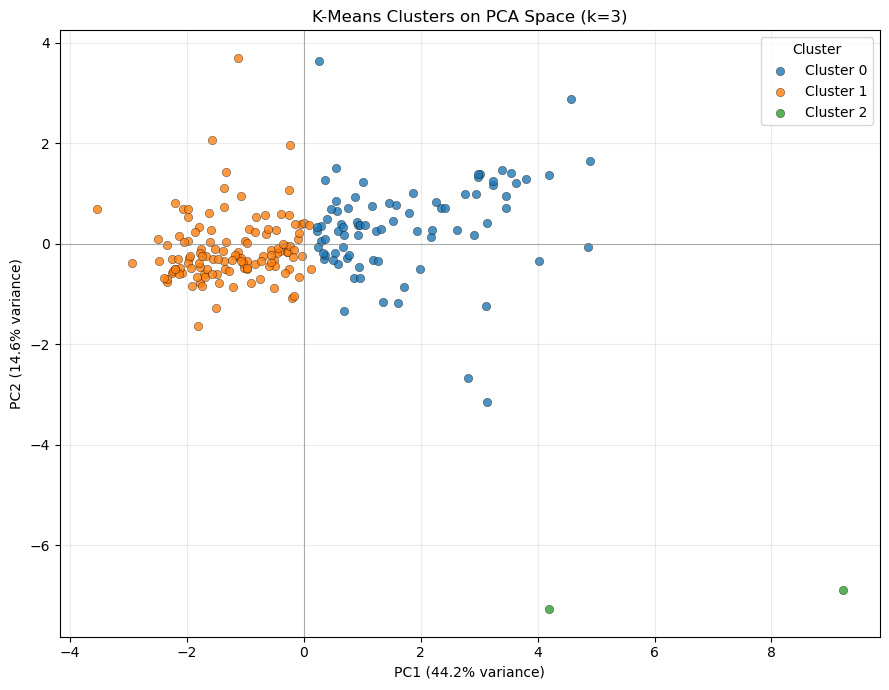

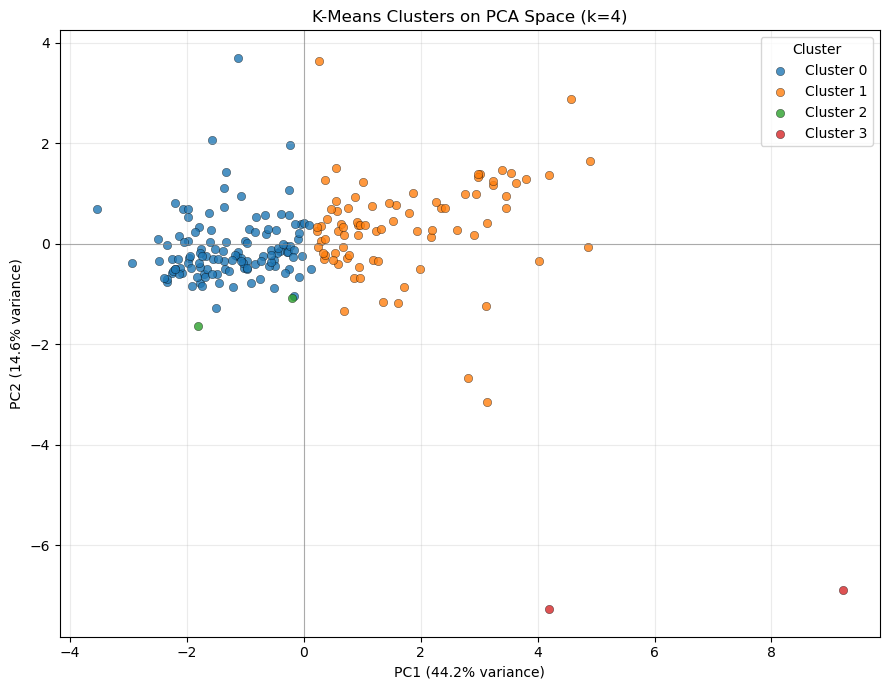

In [29]:
def plot_clusters_on_pca(pca_scores_df, labels, title):
    fig, ax = plt.subplots(figsize=(9, 7))
    unique_labels = sorted(np.unique(labels))

    for label in unique_labels:
        mask = labels == label
        ax.scatter(
            pca_scores_df.loc[mask, "PC1"],
            pca_scores_df.loc[mask, "PC2"],
            label=f"Cluster {label}",
            alpha=0.8,
            edgecolor="black",
            linewidth=0.3,
        )

    ax.axhline(0, color="gray", linewidth=0.8, alpha=0.6)
    ax.axvline(0, color="gray", linewidth=0.8, alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({explained_variance.loc[0, 'explained_variance_ratio']:.1%} variance)")
    ax.set_ylabel(f"PC2 ({explained_variance.loc[1, 'explained_variance_ratio']:.1%} variance)")
    ax.legend(title="Cluster")
    ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

plot_clusters_on_pca(pca_scores, cluster_labels_3, "K-Means Clusters on PCA Space (k=3)")
plot_clusters_on_pca(pca_scores, cluster_labels_4, "K-Means Clusters on PCA Space (k=4)")

### Cluster Interpretation

The code below prints concise summaries of each cluster using the strongest standardized centroid values. Positive values indicate features above the overall average; negative values indicate features below the overall average.

In [30]:
def describe_clusters(standardized_centroids, cluster_sizes, top_n=4):
    descriptions = []
    centroid_features = standardized_centroids.set_index("cluster")

    for cluster_id, row in centroid_features.iterrows():
        strongest = row.abs().sort_values(ascending=False).head(top_n).index
        phrases = []
        for feature in strongest:
            direction = "high" if row[feature] > 0 else "low"
            phrases.append(f"{direction} {feature} ({row[feature]:+.2f} SD)")

        size = int(cluster_sizes.loc[cluster_id, "country_count"])
        description = f"Cluster {cluster_id} (n={size}): " + "; ".join(phrases)
        descriptions.append(description)

    return descriptions

print("Interpretation summaries for k=3:")
for line in describe_clusters(centroids_k3_std, cluster_size_k3):
    print("-", line)

print("\nInterpretation summaries for k=4:")
for line in describe_clusters(centroids_k4_std, cluster_size_k4):
    print("-", line)


Interpretation summaries for k=3:
- Cluster 0 (n=82): high pct_age_65_plus (+0.90 SD); high life_expectancy (+0.83 SD); high urban_population_pct (+0.70 SD); high health_expenditure_per_capita (+0.68 SD)
- Cluster 1 (n=125): low pct_age_65_plus (-0.63 SD); low life_expectancy (-0.57 SD); low gdp_per_capita (-0.50 SD); low urban_population_pct (-0.49 SD)
- Cluster 2 (n=2): high population_density (+9.35 SD); high gdp_per_capita (+4.38 SD); high pct_age_65_plus (+2.14 SD); high urban_population_pct (+1.66 SD)

Interpretation summaries for k=4:
- Cluster 0 (n=123): low pct_age_65_plus (-0.64 SD); low life_expectancy (-0.58 SD); low gdp_per_capita (-0.50 SD); low urban_population_pct (-0.49 SD)
- Cluster 1 (n=82): high pct_age_65_plus (+0.90 SD); high life_expectancy (+0.83 SD); high urban_population_pct (+0.70 SD); high health_expenditure_per_capita (+0.68 SD)
- Cluster 2 (n=2): high population (+9.62 SD); low health_expenditure_pct_gdp (-0.77 SD); low urban_population_pct (-0.55 SD); low

### K-Means Interpretation

The elbow plot does not provide a perfectly clear single choice of `k`. Inertia decreases steadily from `k=1` through `k=10`, so the clustering structure should be treated as exploratory rather than definitive.

Between the two fitted solutions, `k=3` is the preferred interpretation because it produces two large substantive groups and one small outlier group. The `k=4` solution mainly splits out an additional tiny 2-country group, which makes the result less stable and harder to interpret as a general country profile.

For `k=3`, the cluster sizes are approximately 82, 125, and 2 countries. The two-country cluster should be interpreted as an outlier group rather than as a broad global category. It contains Macao SAR, China and Monaco, both of which have extremely high population density and very high income profiles. K-Means is sensitive to this kind of extreme observation because it uses Euclidean distance on standardized variables.

The larger clusters are more substantively interpretable. One cluster contains countries with higher age structure, life expectancy, urbanization, and healthcare spending; representative countries near the centroid include Korea, Cyprus, New Zealand, Czechia, Spain, Israel, and Estonia. Another cluster contains younger and lower-income country profiles, with representative countries such as Senegal, Uzbekistan, Guatemala, Cambodia, Fiji, the Philippines, Egypt, and Belize.

These clusters should not be interpreted as causal groups or fixed categories. They are exploratory summaries of structural similarity across countries. Their main value is showing that the same demographic-development dimensions identified by PCA also organize countries into recognizable profiles.


## Random Forest Classification

Random Forest is a supervised classification method that combines many decision trees. It is useful here because it can capture nonlinear relationships between country-level predictors and the binary `high_mortality` target without requiring strict linear assumptions.

The goal is to predict whether a country belongs to the highest COVID-19 mortality quartile using the same structural predictor variables used in PCA and K-Means.

### Modeling Dataset

Use the same eight continuous structural predictors used in PCA and K-Means. Identifier columns, region labels, quartile labels, COVID outcome variables, and the target itself are excluded from the feature matrix. Missing predictor values are handled with median imputation inside the modeling pipeline.

In [31]:
rf_predictor_cols = [
    "population",
    "gdp_per_capita",
    "life_expectancy",
    "population_density",
    "health_expenditure_per_capita",
    "health_expenditure_pct_gdp",
    "pct_age_65_plus",
    "urban_population_pct",
]

target_col = "high_mortality"

missing_rf_cols = [col for col in rf_predictor_cols + [target_col] if col not in df.columns]
if missing_rf_cols:
    raise ValueError(f"Missing expected Random Forest columns: {missing_rf_cols}")

X = df[rf_predictor_cols].copy()
y = df[target_col].astype(int).copy()

print("Random Forest predictor columns:")
print(rf_predictor_cols)
print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().sort_index())
print("\nMissing values in predictors before imputation:")
display(X.isna().sum().to_frame("missing_count"))

Random Forest predictor columns:
['population', 'gdp_per_capita', 'life_expectancy', 'population_density', 'health_expenditure_per_capita', 'health_expenditure_pct_gdp', 'pct_age_65_plus', 'urban_population_pct']

Feature matrix shape: (209, 8)
Target shape: (209,)

Target distribution:
high_mortality
0    157
1     52
Name: count, dtype: int64

Missing values in predictors before imputation:


,missing_count
population,0
gdp_per_capita,6
life_expectancy,0
population_density,0
health_expenditure_per_capita,17
health_expenditure_pct_gdp,17
pct_age_65_plus,0
urban_population_pct,0


### Train/Test Split

A stratified train/test split preserves the proportion of high-mortality and non-high-mortality countries in both the training and test sets. This matters because the positive class is smaller than the negative class.

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42,
)

print("Training feature matrix:", X_train.shape)
print("Test feature matrix:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTest target distribution:")
print(y_test.value_counts().sort_index())

Training feature matrix: (146, 8)
Test feature matrix: (63, 8)

Training target distribution:
high_mortality
0    110
1     36
Name: count, dtype: int64

Test target distribution:
high_mortality
0    47
1    16
Name: count, dtype: int64


### Fit Random Forest Model

The pipeline first imputes missing predictor values using the training-set median, then fits a Random Forest classifier with 500 trees. The random seed makes the results reproducible.

In [33]:
rf_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=500, random_state=42)),
    ]
)

rf_pipeline.fit(X_train, y_train)

rf_predictions = rf_pipeline.predict(X_test)
rf_probabilities = rf_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest model fit complete.")

Random Forest model fit complete.


### Model Evaluation

Evaluate the model using accuracy, precision, recall, F1 score, and the confusion matrix. Accuracy gives the overall share of correct predictions, while precision and recall are more informative for the high-mortality class.

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions, zero_division=0)
rf_recall = recall_score(y_test, rf_predictions, zero_division=0)
rf_f1 = f1_score(y_test, rf_predictions, zero_division=0)

metrics_table = pd.DataFrame(
    {
        "metric": ["accuracy", "precision", "recall", "f1"],
        "value": [rf_accuracy, rf_precision, rf_recall, rf_f1],
    }
)

display(metrics_table)

print("Classification report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

,metric,value
0,accuracy,0.825397
1,precision,0.631579
2,recall,0.750000
3,f1,0.685714


Classification report:
              precision    recall  f1-score   support

           0       0.91      0.85      0.88        47
           1       0.63      0.75      0.69        16

    accuracy                           0.83        63
   macro avg       0.77      0.80      0.78        63
weighted avg       0.84      0.83      0.83        63



### Confusion Matrix

The confusion matrix shows correct and incorrect predictions by class. Rows are actual classes and columns are predicted classes.

,Predicted 0,Predicted 1
Actual 0,40,7
Actual 1,4,12


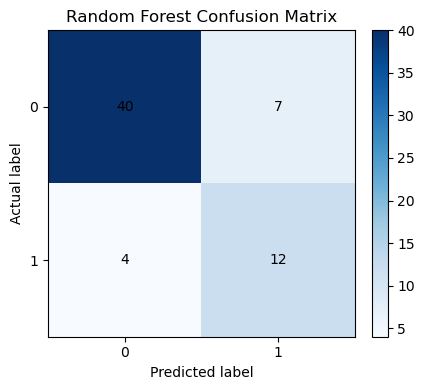

In [35]:
rf_confusion = confusion_matrix(y_test, rf_predictions, labels=[0, 1])
confusion_df = pd.DataFrame(
    rf_confusion,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"],
)

display(confusion_df)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(rf_confusion, cmap="Blues")
ax.set_title("Random Forest Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["0", "1"])
ax.set_yticklabels(["0", "1"])

for i in range(rf_confusion.shape[0]):
    for j in range(rf_confusion.shape[1]):
        ax.text(j, i, rf_confusion[i, j], ha="center", va="center", color="black")

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### Feature Importance

Random Forest feature importance measures how much each predictor contributes to reducing classification error across the trees. It is useful for ranking predictors, but it should be interpreted as association, not causation.

In [36]:
rf_model = rf_pipeline.named_steps["model"]

feature_importance = pd.DataFrame(
    {
        "feature": rf_predictor_cols,
        "importance": rf_model.feature_importances_,
    }
).sort_values("importance", ascending=False)

print("Random Forest feature importance:")
display(feature_importance)

top_5_features = feature_importance.head(5).copy()
print("Top 5 Random Forest predictors:")
display(top_5_features)

Random Forest feature importance:


,feature,importance
6,pct_age_65_plus,0.217417
5,health_expenditure_pct_gdp,0.136293
1,gdp_per_capita,0.136148
4,health_expenditure_per_capita,0.128155
2,life_expectancy,0.123726
3,population_density,0.091518
0,population,0.087406
7,urban_population_pct,0.079337


Top 5 Random Forest predictors:


,feature,importance
6,pct_age_65_plus,0.217417
5,health_expenditure_pct_gdp,0.136293
1,gdp_per_capita,0.136148
4,health_expenditure_per_capita,0.128155
2,life_expectancy,0.123726


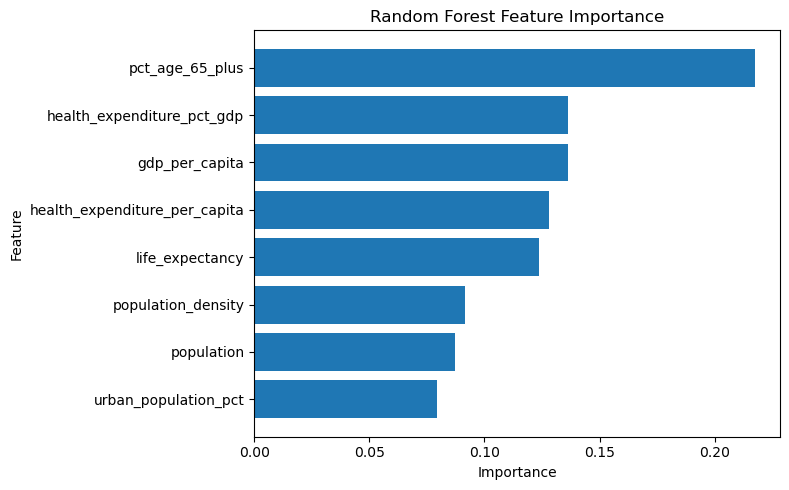

In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_df = feature_importance.sort_values("importance", ascending=True)

ax.barh(plot_df["feature"], plot_df["importance"])
ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

### Random Forest Interpretation

Use the top-ranked predictors to explain which country-level characteristics are most useful for separating high-mortality countries from other countries. Compare these predictors with the PCA loadings and the correlation analysis to see whether the model emphasizes similar structural dimensions.

In [38]:
print("Random Forest interpretation summary:")
print(f"- Model accuracy: {rf_accuracy:.3f}")
print(f"- Precision for high_mortality=1: {rf_precision:.3f}")
print(f"- Recall for high_mortality=1: {rf_recall:.3f}")
print(f"- F1 score for high_mortality=1: {rf_f1:.3f}")

strongest_predictors = top_5_features["feature"].tolist()
print("- Strongest predictors:", ", ".join(strongest_predictors))

print("\nPractical interpretation:")
print(
    "The Random Forest ranks structural country characteristics by how useful they are for predicting membership "
    "in the highest mortality quartile. Compare the strongest predictors here with the PCA loadings and the "
    "correlations with deaths_per_100k. Agreement across these methods strengthens the interpretation; differences "
    "may indicate nonlinear patterns or interactions captured by the Random Forest."
)

Random Forest interpretation summary:
- Model accuracy: 0.825
- Precision for high_mortality=1: 0.632
- Recall for high_mortality=1: 0.750
- F1 score for high_mortality=1: 0.686
- Strongest predictors: pct_age_65_plus, health_expenditure_pct_gdp, gdp_per_capita, health_expenditure_per_capita, life_expectancy

Practical interpretation:
The Random Forest ranks structural country characteristics by how useful they are for predicting membership in the highest mortality quartile. Compare the strongest predictors here with the PCA loadings and the correlations with deaths_per_100k. Agreement across these methods strengthens the interpretation; differences may indicate nonlinear patterns or interactions captured by the Random Forest.


### Random Forest Interpretation and Caveats

The Random Forest achieved approximately 82.5% accuracy on the test set. This should be compared with the majority-class baseline: because about 75% of the test countries are not high mortality, always predicting `high_mortality = 0` would achieve about 74.6% accuracy. The Random Forest improves on this baseline, but the improvement is moderate rather than overwhelming.

Precision, recall, and F1 provide more useful detail for the high-mortality class. Precision describes how often countries predicted as high mortality actually were high mortality. Recall describes how many truly high-mortality countries the model identified. In this project, recall is especially important because missing high-mortality countries would weaken the model's usefulness for identifying countries with severe mortality burden.

The feature importance ranking points to `pct_age_65_plus`, `health_expenditure_pct_gdp`, `gdp_per_capita`, `health_expenditure_per_capita`, and `life_expectancy` as the strongest predictors. These agree with the PCA and correlation findings in emphasizing age structure, development, and healthcare-system characteristics.

However, impurity-based Random Forest feature importance should be interpreted cautiously. Predictors such as GDP per capita, life expectancy, health spending, and age structure are correlated, so importance can be shared or shifted among related variables. Feature importance indicates predictive usefulness in this model, not causal influence.


### Modeling Limitations

Several limitations affect the supervised modeling results. First, the sample size is small: the final dataset contains 209 countries, and the test set contains only 63 countries. As a result, performance metrics may vary under different train/test splits.

Second, the model uses a single stratified train/test split. This is appropriate for a first analysis, but cross-validation would provide a more stable estimate of predictive performance.

Third, the design is cross-sectional. It uses country-level characteristics and cumulative COVID outcomes, so it cannot capture how relationships changed over time.

Fourth, many predictors are correlated. Economic development, life expectancy, healthcare spending, urbanization, and age structure are not independent, which complicates interpretation of feature importance.

Fifth, the analysis is country-level and therefore hides within-country variation. Large countries can contain substantial regional differences in demographics, healthcare capacity, policies, and COVID outcomes.

Finally, the results are associational. The model can identify variables associated with high mortality, but it cannot prove that those variables caused higher mortality.


## Conclusions

### Data Engineering

This project built a cloud-based data engineering pipeline in BigQuery that integrated Johns Hopkins COVID-19 data with World Bank World Development Indicators. The pipeline transformed raw country/province COVID time-series files and country-level development indicators into a single country-level modeling table containing demographic, economic, healthcare, regional, and COVID outcome variables.

The final modeling table provided a clean analytical foundation for exploratory analysis, PCA, clustering, and supervised classification. This workflow demonstrates how cloud storage and SQL-based transformation can support reproducible data preparation before local statistical modeling.

### Exploratory Analysis

The final dataset contains 209 countries. Missingness was limited and concentrated mainly in GDP and health expenditure variables, especially healthcare spending measures. Most core demographic and mortality variables were complete.

COVID mortality outcomes were right-skewed, meaning most countries had relatively moderate mortality rates while a smaller number experienced very high deaths per 100,000 population. Cases per 100,000 and GDP per capita were also right-skewed, reinforcing the need for standardized predictors and careful cross-country interpretation.

### PCA Findings

Principal Component Analysis showed that the first principal component explained approximately 44% of the variance in the standardized predictor set. PC1 was dominated by development-related variables, including GDP per capita, life expectancy, health spending, and age structure.

PC2 captured a different contrast involving healthcare expenditure as a share of GDP and population density. Four principal components explained roughly 81% of the total variance, suggesting that a small number of demographic, economic, and healthcare dimensions summarize much of the predictor structure.

### K-Means Findings

The elbow method suggested approximately 3 to 4 clusters, but it did not provide a perfectly clear choice. The three-cluster solution was more interpretable because it produced two large substantive groups and one small outlier group, while the four-cluster solution mainly introduced another tiny outlier cluster.

The clusters roughly separated countries with older, wealthier, more urbanized, higher-health-spending profiles from countries with younger, lower-income profiles. A small outlier cluster captured extremely dense and wealthy countries such as Macao SAR, China and Monaco. Because K-Means is sensitive to extreme observations, these clusters should be interpreted as exploratory profiles rather than fixed categories.

### Random Forest Findings

The Random Forest classifier predicted the high-mortality target with approximately 82.5% accuracy and approximately 75% recall for high-mortality countries. This performance improved on the majority-class baseline, but the improvement should be interpreted as moderate given the small sample size and single train/test split.

The most important predictors were:

- `pct_age_65_plus`
- `health_expenditure_pct_gdp`
- `gdp_per_capita`
- `health_expenditure_per_capita`
- `life_expectancy`

These predictors indicate that age structure, economic development, and healthcare-system characteristics were useful for distinguishing countries in the highest mortality quartile.

### Overall Interpretation

Across PCA, K-Means clustering, and Random Forest classification, the analysis consistently highlighted related demographic-development dimensions. Older population structure, higher life expectancy, GDP per capita, and healthcare spending appeared repeatedly in the PCA loadings, cluster profiles, correlations, and Random Forest feature importance.

This agreement across methods increases confidence that these country-level characteristics are associated with COVID-19 mortality patterns in the dataset. However, agreement across methods does not prove causality. The findings should be interpreted as descriptive and predictive associations, not evidence that these factors caused higher mortality.

### Limitations

This analysis uses cross-sectional country-level data, so it cannot capture within-country variation or changing pandemic conditions over time. The sample size is limited to 209 countries, which constrains the complexity and stability of machine learning results.

The results are correlational and should not be interpreted as causal. COVID-19 reporting quality, testing availability, death certification practices, and public health policies varied substantially across countries. The findings also depend on the selected COVID time period and the final cumulative Johns Hopkins data used in this project.

### Future Work

Future work could extend the project by incorporating additional years of data, building a time-series analysis, adding more socioeconomic and public health indicators, and comparing alternative machine learning models. Additional robustness checks could examine different mortality thresholds, regional subgroup analyses, cross-validation, permutation importance, or alternative definitions of pandemic burden.
